<a href="https://colab.research.google.com/github/hussainiram0601-lang/cat-dog-classifier-cnn/blob/main/cat_vs_dog_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

In [2]:
!kaggle datasets download -d salader/dogsvscats

Dataset URL: https://www.kaggle.com/datasets/salader/dogsvscats
License(s): unknown
100% 1.06G/1.06G [00:56<00:00, 20.3MB/s]



In [3]:
import zipfile
zip_ref = zipfile.ZipFile('/content/dogsvscats.zip','r')
zip_ref.extractall('/content')
zip_ref.close()

In [4]:
! pip install tensorflow

In [5]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense , Conv2D , MaxPooling2D , Flatten , BatchNormalization , Dropout

In [6]:
# generators - divide data into batches
train = keras.utils.image_dataset_from_directory(
    directory = '/content/train',
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256)
)

val = keras.utils.image_dataset_from_directory(
    directory = '/content/test',
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256)
)


Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [7]:
# Normalize
def process(image, label):
  image = tf.cast(image/255. , tf.float32)
  return image,label

train_ds = train.map(process)
validation_ds = val.map(process)


In [8]:
# create CNN model

model = Sequential()

model.add(Conv2D(32, kernel_size=(3,3), padding = 'valid' , activation ='relu',input_shape = (256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2) , strides = 2 , padding = 'valid'))
model.add(Conv2D(64, kernel_size=(3,3), padding = 'valid' , activation ='relu',input_shape = (256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2) , strides = 2 , padding = 'valid'))
model.add(Conv2D(128, kernel_size=(3,3), padding = 'valid' , activation ='relu',input_shape = (256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2) , strides = 2 , padding = 'valid'))

model.add(Flatten())

model.add(Dense(128 , activation ='relu'))
model.add(Dropout(0.3))
model.add(Dense(64 , activation = 'relu'))
model.add(Dropout(0.1))
model.add(Dense(1, activation='sigmoid'))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [10]:
model.compile(optimizer= 'adam', loss = 'binary_crossentropy', metrics=['accuracy'])

In [11]:
history =model.fit(train_ds, epochs =10, validation_data=validation_ds)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 90s 112ms/step - accuracy: 0.5526 - loss: 1.2419 - val_accuracy: 0.5614 - val_loss: 0.7312
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 63s 101ms/step - accuracy: 0.6058 - loss: 0.6656 - val_accuracy: 0.6040 - val_loss: 0.6467
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 78s 94ms/step - accuracy: 0.6332 - loss: 0.6343 - val_accuracy: 0.7192 - val_loss: 0.5644
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 59s 95ms/step - accuracy: 0.6792 - loss: 0.5735 - val_accuracy: 0.7246 - val_loss: 0.5204
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 85s 100ms/step - accuracy: 0.7258 - loss: 0.5145 - val_accuracy: 0.7094 - val_loss: 0.5575
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 62s 99ms/step - accuracy: 0.7556 - loss: 0.4704 - val_accuracy: 0.7960 - val_loss: 0.4507
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 59s 94ms/step - accuracy: 0.7891 - loss: 0.4260 - val_accuracy: 0.7914 - val_loss: 0.4413
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 59s 94ms/step - accuracy: 0.8109 - loss: 0.3960

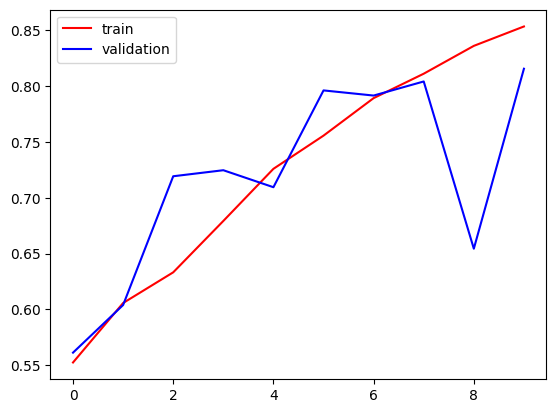

In [12]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'], color ='red', label = 'train')
plt.plot(history.history['val_accuracy'], color = 'blue' , label = 'validation')
plt.legend()
plt.show()

In [13]:
import cv2

In [20]:
test_img = cv2.imread('/content/dog.png')
test_img2 = cv2.imread('/content/cat.png')

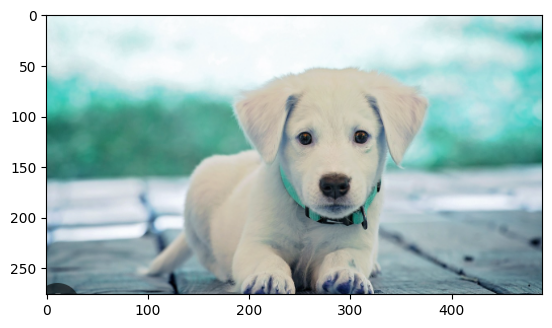

In [21]:
plt.imshow(test_img)

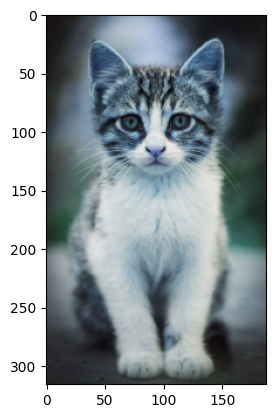

In [22]:
plt.imshow(test_img2)

In [23]:
test_img.shape
test_img2.shape

(316, 188, 3)

In [24]:
test_img = cv2.resize(test_img,(256,256))
test_img2 = cv2.resize(test_img2,(256,256))

In [25]:
test_input = test_img.reshape((1,256,256,3))
test_input2 = test_img2.reshape((1,256,256,3))

In [26]:
print(f'dog input {model.predict(test_input)}')
print(f'cat input {model.predict(test_input2)}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
dog input [[1.]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
cat input [[1.]]
